# CodeAlpha Task 1 - Web Scraping

## Book Data Collection and Analysis

This project focuses on collecting book information from the Books to Scrape website using Python and BeautifulSoup. The collected data is cleaned, analyzed, and visualized to understand book prices and ratings.


## Objective

The main objective of this project is to:

- Scrape book information from a website.
- Collect data from multiple web pages.
- Create a structured dataset using Pandas.
- Clean and prepare the scraped data.
- Analyze book prices and ratings.
- Create visualizations to understand the collected data.

## Technologies Used

- Python
- Google Colab
- Requests
- BeautifulSoup
- Pandas
- Matplotlib

## Methodology

The project was completed through the following steps:

1. Selected the Books to Scrape website.
2. Sent requests to the website using Python.
3. Parsed the HTML using BeautifulSoup.
4. Extracted book titles, prices, and ratings.
5. Scraped data from multiple pages.
6. Created a dataset containing 100 books.
7. Cleaned and converted the price and rating columns.
8. Performed basic analysis of book prices and ratings.
9. Created visualizations for price and rating distributions.
10. Saved the final cleaned dataset as a CSV file.

## 1. Import Required Libraries

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Connect to the Website

In [3]:
url = "https://books.toscrape.com/"

response = requests.get(url)

print("Status Code:", response.status_code)

Status Code: 200


## 3. Parse the Web Page

In [4]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)


    All products | Books to Scrape - Sandbox



## 4. Extract Book Data

In [5]:
books = soup.find_all("article", class_="product_pod")

print("Number of books found:", len(books))

Number of books found: 20


In [6]:
first_book = books[0]

title = first_book.h3.a["title"]
price = first_book.find("p", class_="price_color").text
rating = first_book.p["class"][1]

print("Title:", title)
print("Price:", price)
print("Rating:", rating)

Title: A Light in the Attic
Price: Â£51.77
Rating: Three


In [7]:
data = []

for book in books:
    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.p["class"][1]

    data.append({
        "Title": title,
        "Price": price,
        "Rating": rating
    })

df = pd.DataFrame(data)

df.head()

,Title,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


In [8]:
df.shape

(20, 3)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Title   20 non-null     object
 1   Price   20 non-null     object
 2   Rating  20 non-null     object
dtypes: object(3)
memory usage: 612.0+ bytes


In [10]:
df.isnull().sum()

,0
Title,0
Price,0
Rating,0


In [11]:
df.to_csv("books_scraped.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


## 5. Multi-Page Web Scraping

In [12]:
all_books = []

for page in range(1, 6):
    if page == 1:
        url = "https://books.toscrape.com/"
    else:
        url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")

    for book in books:
        title = book.h3.a["title"]
        price = book.find("p", class_="price_color").text
        rating = book.p["class"][1]

        all_books.append({
            "Title": title,
            "Price": price,
            "Rating": rating
        })

print("Total books scraped:", len(all_books))

Total books scraped: 100


## 6. Create the Dataset

In [13]:
df = pd.DataFrame(all_books)

df.head()

,Title,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


In [14]:
df.shape

(100, 3)

In [15]:
df.tail()

,Title,Price,Rating
95,Lumberjanes Vol. 3: A Terrible Plan (Lumberjan...,Â£19.92,Two
96,"Layered: Baking, Building, and Styling Spectac...",Â£40.11,One
97,Judo: Seven Steps to Black Belt (an Introducto...,Â£53.90,Two
98,Join,Â£35.67,Five
99,In the Country We Love: My Family Divided,Â£22.00,Four


In [16]:
df.isnull().sum()

,0
Title,0
Price,0
Rating,0


In [17]:
df.to_csv("books_scraped_100.csv", index=False)

print("100-book dataset saved successfully!")

100-book dataset saved successfully!


## 7. Data Cleaning

In [18]:
df["Price"] = df["Price"].astype(str).str.extract(r'([\d.]+)')[0].astype(float)

df.head()

,Title,Price,Rating
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five


In [19]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

df.head()

,Title,Price,Rating
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Title   100 non-null    object 
 1   Price   100 non-null    float64
 2   Rating  100 non-null    int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 2.5+ KB


## 8. Data Analysis

In [21]:
average_price = df["Price"].mean()

print("Average book price: £", round(average_price, 2))

Average book price: £ 34.56


In [22]:
cheapest_book = df.loc[df["Price"].idxmin()]

print("Cheapest book:", cheapest_book["Title"])
print("Price: £", cheapest_book["Price"])

Cheapest book: Patience
Price: £ 10.16


In [23]:
expensive_book = df.loc[df["Price"].idxmax()]

print("Most expensive book:", expensive_book["Title"])
print("Price: £", expensive_book["Price"])

Most expensive book: The Death of Humanity: and the Case for Life
Price: £ 58.11


## 9. Data Visualization

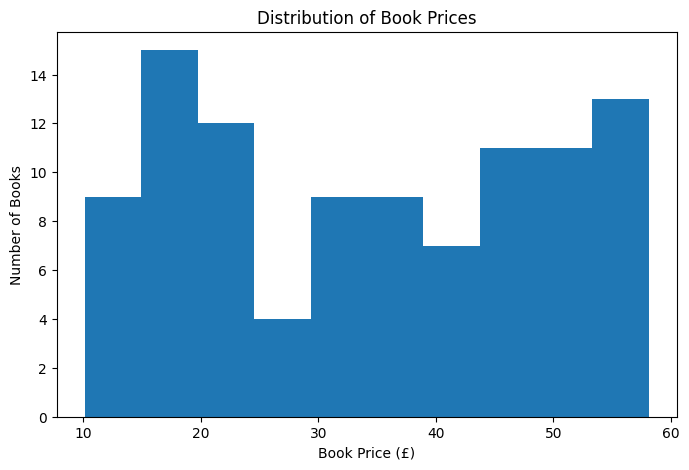

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=10)

plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Prices")

plt.show()

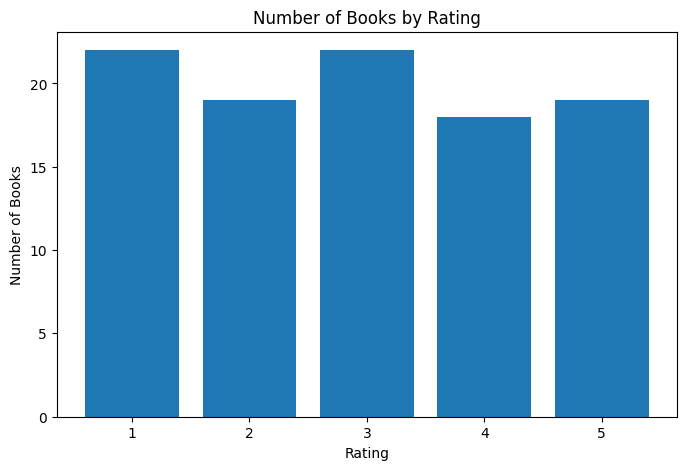

In [25]:
rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(rating_counts.index, rating_counts.values)

plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.title("Number of Books by Rating")

plt.xticks([1, 2, 3, 4, 5])

plt.show()

In [26]:
print("Books by rating:")
print(rating_counts)

Books by rating:
Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


In [27]:
df.to_csv("CodeAlpha_Task1_Final_Dataset.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [28]:
average_rating = df["Rating"].mean()

print("Average book rating:", round(average_rating, 2))

Average book rating: 2.93


In [29]:
summary = pd.DataFrame({
    "Metric": [
        "Total Books",
        "Average Price",
        "Minimum Price",
        "Maximum Price",
        "Average Rating"
    ],
    "Value": [
        len(df),
        round(df["Price"].mean(), 2),
        round(df["Price"].min(), 2),
        round(df["Price"].max(), 2),
        round(df["Rating"].mean(), 2)
    ]
})

summary

,Metric,Value
0,Total Books,100.00
1,Average Price,34.56
2,Minimum Price,10.16
3,Maximum Price,58.11
4,Average Rating,2.93


In [30]:
df.to_csv("CodeAlpha_Task1_Final_Dataset.csv", index=False)

print("Final dataset updated successfully!")

Final dataset updated successfully!


## 10. Key Findings

- A total of 100 books were collected from multiple pages of the Books to Scrape website.
- The average book price is £34.56.
- The minimum book price is £10.16.
- The maximum book price is £58.11.
- The average book rating is 2.93 out of 5.
- Ratings of 1 and 3 were the most common, with 22 books each.
- Rating 4 was given to 18 books, while ratings 2 and 5 were given to 19 books each.
- The visualizations help understand the distribution of book prices and ratings.

## 11. Conclusion

In this project, book data was successfully collected from multiple pages of the Books to Scrape website using Python and BeautifulSoup. The scraped data was cleaned and organized using Pandas.

The analysis provided useful insights into book prices and ratings. The visualizations made it easier to understand the patterns in the collected dataset. The final cleaned dataset was saved as a CSV file for further use.